# 1. Scaled Dot-Product Attention

## Objective

Implement scaled dot-product attention using PyTorch and understand how Query (Q), Key (K), and Value (V) tensors are used to calculate the attention output.

## Formula

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

## Steps

1. Create Query, Key, and Value tensors.
2. Calculate similarity scores using \(QK^T\).
3. Scale the scores by dividing by \(\sqrt{d_k}\).
4. Apply softmax to calculate attention weights.
5. Multiply the attention weights by the Value tensor.
6. Inspect the tensor shapes and numerical outputs.

## Key distinction

* **Attention scores:** Raw similarity scores between queries and keys.
* **Attention weights:** Normalized scores obtained using softmax.
* **Attention output:** Weighted sum of the value vectors.

The attention output is a new representation containing information from the value vectors, weighted according to their relevance to the query.


In [1]:
import torch
import torch.nn.functional as F

# Example: one query attends to three key-value pairs
Q = torch.tensor([[1.0, 0.0]])

K = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0]
])

V = torch.tensor([
    [10.0, 0.0],
    [0.0, 10.0],
    [5.0, 5.0]
])

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([1, 2])
K shape: torch.Size([3, 2])
V shape: torch.Size([3, 2])


In [6]:
K.ndim

2

In [2]:
# Step 2: Calculate attention scores

scores = Q @ K.T

print("Attention scores:", scores)
print("Scores shape:", scores.shape)

Attention scores: tensor([[1., 0., 1.]])
Scores shape: torch.Size([1, 3])


Scaling does not change which score is largest in this example. It reduces the magnitude of the scores before softmax.

The scaling factor is determined by the key-vector dimension, \(d_k\), not the number of keys.

In [3]:
# Step 3: Scale the attention scores

d_k = K.shape[-1]

scaled_scores = scores / (d_k ** 0.5)

print("Key dimension:", d_k)
print("Scaled scores:", scaled_scores)

Key dimension: 2
Scaled scores: tensor([[0.7071, 0.0000, 0.7071]])


In [4]:
# Step 4: Convert scaled scores into attention weights

attention_weights = F.softmax(scaled_scores, dim=-1)

print("Attention weights:", attention_weights)
print("Sum of weights:", attention_weights.sum(dim=-1))

Attention weights: tensor([[0.4011, 0.1978, 0.4011]])
Sum of weights: tensor([1.])


In [5]:
# Step 5: Calculate the attention output

attention_output = attention_weights @ V

print("Attention output:", attention_output)
print("Output shape:", attention_output.shape)

Attention output: tensor([[6.0167, 3.9833]])
Output shape: torch.Size([1, 2])


# **SELF - ATTENTION**

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)

# Three tokens, each represented by four features
X = torch.tensor([
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 2.0, 0.0, 2.0],
    [1.0, 1.0, 1.0, 1.0]
])

print("Input X:\n", X)
print("Input shape:", X.shape)

Input X:
 tensor([[1., 0., 1., 0.],
        [0., 2., 0., 2.],
        [1., 1., 1., 1.]])
Input shape: torch.Size([3, 4])


In [8]:
d_model = 4
d_k = 4
d_v = 4

W_Q = nn.Linear(d_model, d_k, bias=False)
W_K = nn.Linear(d_model, d_k, bias=False)
W_V = nn.Linear(d_model, d_v, bias=False)

Q = W_Q(X)
K = W_K(X)
V = W_V(X)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([3, 4])
K shape: torch.Size([3, 4])
V shape: torch.Size([3, 4])


In [10]:
# Step 1: Calculate attention scores
scores = Q @ K.T

# Step 2: Scale the scores
scaled_scores = scores / (d_k ** 0.5)

# Step 3: Calculate attention weights
attention_weights = F.softmax(scaled_scores, dim=-1)

# Step 4: Calculate the output representations
output = attention_weights @ V

print("Attention scores shape:", scores.shape)
print("Attention weights shape:", attention_weights.shape)
print("Output shape:", output.shape)

print("\nAttention weights:\n", attention_weights)
print("\nOutput representations:\n", output)

Attention scores shape: torch.Size([3, 3])
Attention weights shape: torch.Size([3, 3])
Output shape: torch.Size([3, 4])

Attention weights:
 tensor([[0.5196, 0.1759, 0.3045],
        [0.2141, 0.4562, 0.3297],
        [0.4502, 0.2224, 0.3274]], grad_fn=<SoftmaxBackward0>)

Output representations:
 tensor([[0.4417, 0.2709, 0.4881, 0.3913],
        [0.6087, 0.3780, 0.5735, 0.1538],
        [0.4768, 0.2933, 0.5081, 0.3494]], grad_fn=<MmBackward0>)


# **PADDING**

| Mask         | Purpose                             | Common use                             |
| ------------ | ----------------------------------- | -------------------------------------- |
| Padding mask | Prevent attention to padding tokens | BERT and many other Transformer models |
| Causal mask  | Prevent attention to future tokens  | GPT-style language models              |


## 3.1 Padding Masks

A padding mask prevents the attention mechanism from attending to padding tokens.

When sequences of different lengths are placed into the same batch, padding tokens may be added so that every sequence has the same length.

The mask identifies valid tokens and padding tokens.

Before softmax, the attention scores corresponding to padding key positions are set to a very large negative value, commonly negative infinity.

After softmax, those positions receive zero attention weight.

**Important:** Padding masks generally mask key positions. They do not necessarily force the attention outputs at padded query positions to zero.


In [11]:
import torch
import torch.nn.functional as F

scores = torch.tensor([
    [2.0, 1.0, 3.0],
    [1.0, 2.0, 4.0],
    [3.0, 1.0, 2.0]
])

print("Attention scores:\n", scores)

Attention scores:
 tensor([[2., 1., 3.],
        [1., 2., 4.],
        [3., 1., 2.]])


In [12]:
# True = valid key position
# False = padding key position

valid_keys = torch.tensor([True, True, False])

print("Valid key positions:", valid_keys)

Valid key positions: tensor([ True,  True, False])


#### **`torch.Tensor.masked_fill`**

In [ ]:
masked_scores = scores.masked_fill(~valid_keys.unsqueeze(0),float("-inf")) # (mask, value)

print("Masked scores:\n", masked_scores)

Masked scores:
 tensor([[2., 1., -inf],
        [1., 2., -inf],
        [3., 1., -inf]])


In [14]:
padding_weights = F.softmax(masked_scores, dim=-1)

print("Attention weights after masking:\n", padding_weights)
print("Row sums:", padding_weights.sum(dim=-1))

Attention weights after masking:
 tensor([[0.7311, 0.2689, 0.0000],
        [0.2689, 0.7311, 0.0000],
        [0.8808, 0.1192, 0.0000]])
Row sums: tensor([1.0000, 1.0000, 1.0000])


## 3.2 Causal Masks

A causal mask prevents a token from attending to future tokens in a sequence.

It is essential for autoregressive language models such as GPT.

For a sequence of length \(L\), the causal mask allows attention to the current token and earlier positions while blocking future positions.

The mask is applied to attention scores before softmax.

Future positions are assigned negative infinity, causing their attention weights to become zero after softmax.


In [15]:
scores = torch.tensor([
    [2.0, 1.0, 3.0, 4.0],
    [1.0, 2.0, 3.0, 4.0],
    [3.0, 2.0, 1.0, 4.0],
    [4.0, 3.0, 2.0, 1.0]
])

print("Attention scores:\n", scores)

Attention scores:
 tensor([[2., 1., 3., 4.],
        [1., 2., 3., 4.],
        [3., 2., 1., 4.],
        [4., 3., 2., 1.]])


In [19]:
scores.shape

torch.Size([4, 4])

In [16]:
seq_len = scores.shape[0]

causal_mask = torch.tril(
    torch.ones(seq_len, seq_len, dtype=torch.bool)
)

print("Causal mask:\n", causal_mask)

Causal mask:
 tensor([[ True, False, False, False],
        [ True,  True, False, False],
        [ True,  True,  True, False],
        [ True,  True,  True,  True]])


In [20]:
masked_scores = scores.masked_fill(
    ~causal_mask,
    float("-inf")
)

print("Causally masked scores:\n", masked_scores)

Causally masked scores:
 tensor([[2., -inf, -inf, -inf],
        [1., 2., -inf, -inf],
        [3., 2., 1., -inf],
        [4., 3., 2., 1.]])


In [21]:
masked_scores = scores.masked_fill(
    ~causal_mask,
    float("-inf")
)

print("Causally masked scores:\n", masked_scores)

Causally masked scores:
 tensor([[2., -inf, -inf, -inf],
        [1., 2., -inf, -inf],
        [3., 2., 1., -inf],
        [4., 3., 2., 1.]])


| Property           | Padding mask                         | Causal mask                                    |
| ------------------ | ------------------------------------ | ---------------------------------------------- |
| Main purpose       | Ignore padding key positions         | Prevent access to future positions             |
| Typical use        | Batched sequences of unequal lengths | Autoregressive language models                 |
| What gets blocked? | Padding keys                         | Future keys                                    |
| Used in BERT?      | Commonly, yes                        | No causal mask in standard BERT self-attention |
| Used in GPT?       | When padding is present, yes         | Yes                                            |


# **MULTI - HEAD ATTENTION**

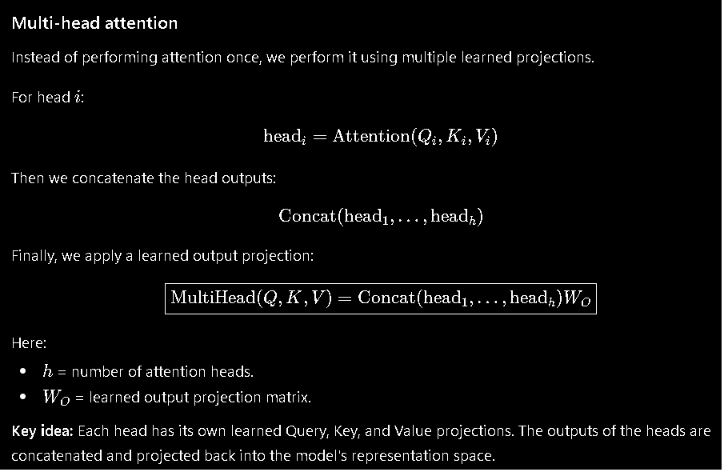

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)

batch_size = 2      # B = 2 sentences at once
seq_len = 3         # L = 3 words per sentence
d_model = 8         # d_model = 8 features per word embedding
num_heads = 2       # h = 2 attention heads splitting the work

assert d_model % num_heads == 0 # Checking to divide the embedding tokens  equally into all the heads

head_dim = d_model // num_heads  # Dividing equally those embeddings 

X = torch.randn(batch_size, seq_len, d_model) 

print("Input shape:", X.shape)
print("Head dimension:", head_dim)

Input shape: torch.Size([2, 3, 8])
Head dimension: 4


In [26]:
X

tensor([[[ 1.9269,  1.4873,  0.9007, -2.1055,  0.6784, -1.2345, -0.0431,
          -1.6047],
         [-0.7521,  1.6487, -0.3925, -1.4036, -0.7279, -0.5594, -0.7688,
           0.7624],
         [ 1.6423, -0.1596, -0.4974,  0.4396, -0.7581,  1.0783,  0.8008,
           1.6806]],

        [[ 1.2791,  1.2964,  0.6105,  1.3347, -0.2316,  0.0418, -0.2516,
           0.8599],
         [-1.3847, -0.8712, -0.2234,  1.7174,  0.3189, -0.4245,  0.3057,
          -0.7746],
         [-1.5576,  0.9956, -0.8798, -0.6011, -1.2742,  2.1228, -1.2347,
          -0.4879]]])

In [35]:
W_Q = nn.Linear(d_model, d_model)
W_K = nn.Linear(d_model, d_model)
W_V = nn.Linear(d_model, d_model)

W_O = nn.Linear(d_model, d_model)

Q = W_Q(X)
K = W_K(X)
V = W_V(X)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([2, 3, 8])
K shape: torch.Size([2, 3, 8])
V shape: torch.Size([2, 3, 8])


### **Spliit**

In [27]:
X.shape

torch.Size([2, 3, 8])

In [36]:
def split_heads(x, num_heads):
    batch_size, seq_len, d_model = x.shape
    head_dim = d_model // num_heads

    x = x.reshape(
        batch_size,
        seq_len,
        num_heads,
        head_dim
    )

    x = x.transpose(1, 2)

    return x

In [37]:
Q_heads = split_heads(Q, num_heads)
K_heads = split_heads(K, num_heads)
V_heads = split_heads(V, num_heads)

print("Q heads:", Q_heads.shape)
print("K heads:", K_heads.shape)
print("V heads:", V_heads.shape)

Q heads: torch.Size([2, 2, 3, 4])
K heads: torch.Size([2, 2, 3, 4])
V heads: torch.Size([2, 2, 3, 4])


In [38]:
scores = Q_heads @ K_heads.transpose(-2, -1)

print("Scores shape:", scores.shape)

Scores shape: torch.Size([2, 2, 3, 3])


In [49]:
scores

tensor([[[[-0.2667, -0.7227,  1.1080],
          [-0.1354,  0.2345,  0.0470],
          [ 1.5517, -0.0030, -2.6754]],

         [[ 0.0555, -0.9703, -0.4131],
          [-0.5294,  0.3178,  0.4001],
          [-1.6288,  0.0161, -0.3950]]],


        [[[-0.1564, -0.4689,  0.3722],
          [ 0.1561, -1.5421,  1.4556],
          [-0.0443, -1.2613,  0.9675]],

         [[ 1.4313,  1.1801,  0.3012],
          [-0.0602,  0.2381,  0.0602],
          [ 1.1437, -0.5166, -0.5786]]]], grad_fn=<UnsafeViewBackward0>)

In [52]:
scaled_scores = scores / (head_dim ** 0.5)

attention_weights = F.softmax(
    scaled_scores,
    dim=-1
)

print("Attention weights shape: [batch_size, num_heads, seq_len, seq_len]", attention_weights.shape)
print("Weights for batch 1, head 1:\n", attention_weights[0, 0])

Attention weights shape: [batch_size, num_heads, seq_len, seq_len] torch.Size([2, 2, 3, 3])
Weights for batch 1, head 1:
 tensor([[0.2642, 0.2104, 0.5254],
        [0.3032, 0.3647, 0.3321],
        [0.6327, 0.2908, 0.0764]], grad_fn=<SelectBackward0>)


In [50]:
attention_weights

tensor([[[[0.2642, 0.2104, 0.5254],
          [0.3032, 0.3647, 0.3321],
          [0.6327, 0.2908, 0.0764]],

         [[0.4184, 0.2505, 0.3310],
          [0.2428, 0.3708, 0.3864],
          [0.1950, 0.4437, 0.3613]]],


        [[[0.3167, 0.2709, 0.4125],
          [0.2991, 0.1280, 0.5729],
          [0.3122, 0.1699, 0.5178]],

         [[0.4081, 0.3599, 0.2319],
          [0.3103, 0.3602, 0.3295],
          [0.5380, 0.2346, 0.2274]]]], grad_fn=<SoftmaxBackward0>)

In [40]:
head_outputs = attention_weights @ V_heads

print("Head outputs shape:", head_outputs.shape)

Head outputs shape: torch.Size([2, 2, 3, 4])


In [51]:
head_outputs

tensor([[[[ 0.8022, -1.1079,  0.2792,  0.2637],
          [ 0.8108, -0.8524,  0.2919,  0.2369],
          [ 0.9377, -0.4697, -0.0520,  0.1988]],

         [[ 0.1128,  0.1816,  0.5455,  0.2236],
          [ 0.3043, -0.1175,  0.5078,  0.0384],
          [ 0.4301, -0.1505,  0.5123,  0.0631]]],


        [[[ 0.1189, -0.1087,  0.3472,  0.3639],
          [ 0.1864, -0.2401,  0.3112,  0.5643],
          [ 0.1729, -0.2052,  0.3288,  0.4979]],

         [[ 0.6121, -0.1075, -0.0892, -0.2956],
          [ 0.5862, -0.1889, -0.1127, -0.1812],
          [ 0.6527, -0.0132, -0.0545, -0.3432]]]],
       grad_fn=<UnsafeViewBackward0>)

| Tensor                         | Shape          | Dimensions                          |
| ------------------------------ | -------------- | ----------------------------------- |
| `attention_weights`            | `[2, 2, 3, 3]` | Batch, head, query, key             |
| `V_heads`                      | `[2, 2, 3, 4]` | Batch, head, token, features        |
| `head_outputs`                 | `[2, 2, 3, 4]` | Batch, head, query, output features |
| `output` after combining heads | `[2, 3, 8]`    | Batch, token, model features        |


In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class MultiHeadAttention(nn.Module):

    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)

        self.W_O = nn.Linear(d_model, d_model)

    def split_heads(self, x):

        batch_size, seq_len, _ = x.shape

        x = x.reshape(
            batch_size,
            seq_len,
            self.num_heads,
            self.head_dim
        )

        return x.transpose(1, 2)

    def forward(self, x, mask=None):

        # 1. Create queries, keys, and values
        Q = self.split_heads(self.W_Q(x))
        K = self.split_heads(self.W_K(x))
        V = self.split_heads(self.W_V(x))

        # 2. Calculate attention scores
        scores = Q @ K.transpose(-2, -1)

        # 3. Scale scores
        scores = scores / (self.head_dim ** 0.5)

        # 4. Apply optional attention mask
        if mask is not None:
            scores = scores.masked_fill(
                ~mask,
                float("-inf")
            )

        # 5. Convert scores into attention weights
        weights = F.softmax(scores, dim=-1)

        # 6. Calculate each head's output
        head_outputs = weights @ V

        # 7. Combine attention heads
        combined = head_outputs.transpose(1, 2).contiguous()

        batch_size, num_heads, seq_len, head_dim = head_outputs.shape

        combined = combined.reshape(
            batch_size,
            seq_len,
            self.d_model
        )

        # 8. Apply final output projection
        output = self.W_O(combined)

        return output, weights

In [45]:
model = MultiHeadAttention(
    d_model=8,
    num_heads=2
)

X = torch.randn(2, 3, 8)

output, weights = model(X)

print("Input shape:", X.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)

Input shape: torch.Size([2, 3, 8])
Output shape: torch.Size([2, 3, 8])
Attention weights shape: torch.Size([2, 2, 3, 3])


# 5. Positional Information and Positional Encoding

## 5.1 Why Do Transformers Need Positional Information?

Before understanding positional encoding, we need to understand one limitation of self-attention.

Consider this sentence:

**"The dog chased the cat."**

Now consider another sentence:

**"The cat chased the dog."**

Both sentences contain almost the same words, but their meanings are different because the words appear in different positions.

In the first sentence, the dog performs the action.

In the second sentence, the cat performs the action.

Therefore, word order is important for understanding language.

### What happens inside self-attention?

In self-attention, we calculate:

$$
Q=XW_Q
$$

$$
K=XW_K
$$

$$
V=XW_V
$$

Then:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

Here:

* \(X\) contains the input token representations.
* \(Q\) contains queries.
* \(K\) contains keys.
* \(V\) contains values.
* The attention mechanism determines how tokens gather information from other tokens.

The important point is that ordinary self-attention does not inherently know whether a token appeared first, second, or third in the sentence.

It calculates relationships between token representations, but it does not automatically receive an explicit position number for each token.

### An ELI5 example

Imagine that I give you these three word cards:

* Dog
* Chased
* Cat

If I shuffle the cards, the words remain the same, but the sentence order changes.

A Transformer needs a way to represent this positional information.

We can provide information such as:

* Dog is at position 0.
* Chased is at position 1.
* Cat is at position 2.

However, simply adding the integer 0, 1, or 2 to a word representation is not necessarily the best approach.

Instead, we can represent each position using a vector of numbers.

This vector is called a **positional encoding** or, more generally, a positional representation.

---

## 5.2 What Is Positional Encoding?

Positional encoding is a way of giving a Transformer information about the positions of tokens in a sequence.

Each token has an embedding vector, and each position has a positional vector.

We combine them before passing the result to the Transformer layers.

The standard additive approach is:

$$
\boxed{X_{\text{input}}=E+P}
$$

Where:

* \(E\) is the token embedding matrix.
* \(P\) is the positional encoding matrix.
* \(X_{\text{input}}\) is the representation passed to the Transformer.

Suppose we have three tokens and each token embedding contains four features.

Then:

$$
E\in\mathbb{R}^{3\times4}
$$

The positional encoding must have the same shape:

$$
P\in\mathbb{R}^{3\times4}
$$

We add the two matrices element by element:

$$
X_{\text{input}}=E+P
$$

The resulting shape is still:

$$
X_{\text{input}}\in\mathbb{R}^{3\times4}
$$

**Important:** Positional encoding does not increase the number of features. It changes the information represented by those features.

### A numerical example

Suppose one token has the embedding:

$$
E_1=[0.2,\ 0.5,\ 0.1,\ 0.7]
$$

Its positional vector is:

$$
P_1=[0.0,\ 1.0,\ 0.0,\ 1.0]
$$

Adding them gives:

$$
X_1=E_1+P_1
$$

Therefore:

$$
X_1=[0.2,\ 1.5,\ 0.1,\ 1.7]
$$

The token embedding contains information about the token, while the positional vector introduces information about its position.

The Transformer receives the combined representation.

The actual positional encodings used in a Transformer are usually generated systematically rather than chosen arbitrarily as in this simple example.

---

## 5.3 Why Not Just Give Every Token Its Position Number?

One possible approach is to assign integer positions:

$$
0,\ 1,\ 2,\ 3,\ldots
$$

But the Transformer operates on vector representations.

We want positional information to work naturally with these vectors and to provide distinguishable representations for different positions.

One solution is to create a positional vector for every position.

For example:

$$
P_0=[0.1,\ 0.2,\ 0.3,\ 0.4]
$$

$$
P_1=[0.2,\ 0.5,\ 0.1,\ 0.7]
$$

$$
P_2=[0.8,\ 0.1,\ 0.6,\ 0.3]
$$

These are illustrative vectors, not the actual sinusoidal values.

Each position receives a vector that can be added to the corresponding token embedding.

There are several ways to produce positional representations.

Two important approaches are:

1. Sinusoidal positional encoding.
2. Learned positional embeddings.

We will implement sinusoidal positional encoding first.

---

## 5.4 Sinusoidal Positional Encoding

The original Transformer architecture introduced sinusoidal positional encodings.

These encodings are constructed using sine and cosine functions at different frequencies.

The formulas are:

For even feature indices:

$$
\boxed{
PE(pos,2i)
=
\sin\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
}
$$

For odd feature indices:

$$
\boxed{
PE(pos,2i+1)
=
\cos\left(
\frac{pos}{10000^{2i/d_{\text{model}}}}
\right)
}
$$

Let's understand every variable.

### What is \(pos\)?

\(pos\) is the position of a token in the sequence.

For a sequence containing five tokens, the positions are:

$$
pos=[0,1,2,3,4]
$$

In our PyTorch implementation, these positions will be represented by a tensor.

### What is \(i\)?

\(i\) identifies a pair of embedding dimensions.

For example, suppose:

$$
d_{\text{model}}=8
$$

The feature indices are:

$$
0,1,2,3,4,5,6,7
$$

The even indices are:

$$
0,2,4,6
$$

The odd indices are:

$$
1,3,5,7
$$

Each even-indexed feature uses sine, and the following odd-indexed feature uses cosine.

The two features in each pair use the same frequency.

### What is \(d_{\text{model}}\)?

It is the number of features in each token representation.

For example:

* \(d_{\text{model}}=4\): four features per token.
* \(d_{\text{model}}=8\): eight features per token.
* \(d_{\text{model}}=512\): 512 features per token.

The positional encoding must use the same model dimension as the token embeddings when the two are added directly.

### Why do we divide by \(10000^{2i/d_{\text{model}}}\)?

This expression determines the frequency used for each pair of features.

Different feature pairs use different frequencies.

Some dimensions change relatively quickly with position, while others change more slowly.

This gives the model a variety of positional patterns instead of repeating the same pattern across every feature.

The constant \(10000\) is part of the original Transformer formulation.

### Why use both sine and cosine?

Sine and cosine provide two complementary patterns.

Using them together creates distinguishable positional vectors across positions and frequencies.

The model can learn to use these patterns when processing token representations.

### Example with \(d_{\text{model}}=4\)

For four features, we have two pairs:

| Feature index | Function | Pair index |
| ------------- | -------- | ---------- |
| 0             | Sine     | 0          |
| 1             | Cosine   | 0          |
| 2             | Sine     | 1          |
| 3             | Cosine   | 1          |

For position \(pos=0\):

$$
PE(0,0)=\sin(0)=0
$$

$$
PE(0,1)=\cos(0)=1
$$

$$
PE(0,2)=\sin(0)=0
$$

$$
PE(0,3)=\cos(0)=1
$$

Therefore:

$$
\boxed{PE(0)=[0,1,0,1]}
$$

For position \(pos=1\), the values are:

$$
PE(1,0)=\sin(1)
$$

$$
PE(1,1)=\cos(1)
$$

$$
PE(1,2)=\sin\left(\frac{1}{10000^{2/4}}\right)
$$

$$
PE(1,3)=\cos\left(\frac{1}{10000^{2/4}}\right)
$$

Since:

$$
10000^{2/4}=100
$$

we obtain:

$$
PE(1)=
[\sin(1),\cos(1),\sin(0.01),\cos(0.01)]
$$

Approximately:

$$
PE(1)=
[0.8415,\ 0.5403,\ 0.0100,\ 0.99995]
$$

Notice that the first pair changes more quickly than the second pair.

This is how different frequencies produce different positional patterns.

---

## 5.5 Why Are Sinusoidal Encodings Useful?

### 1. They provide information about token order

Different positions receive different positional vectors.

Adding these vectors to token embeddings gives the model access to information about where tokens occur.

### 2. They use multiple frequencies

Different dimensions represent positional patterns at different frequencies.

This provides more varied information than assigning the same positional pattern to every feature.

### 3. They are deterministic

The encoding is calculated using a mathematical formula.

There is no need to train a separate parameter for every position.

### 4. They can be calculated for positions beyond those previously encountered

Because the values are generated from formulas, we can calculate encodings for larger positions without learning a new positional vector for each one.

However, this does not guarantee that a Transformer will generalize perfectly to longer sequences. The model's training, architecture, and other design choices still matter.

---

## 5.6 Sinusoidal Encoding vs. Learned Positional Embeddings

Another common approach is to learn a positional embedding for each position.

In this approach, the model maintains a trainable vector for each supported position.

| Property                        | Sinusoidal encoding                    | Learned positional embedding                      |
| ------------------------------- | -------------------------------------- | ------------------------------------------------- |
| How values are obtained         | Mathematical formulas                  | Learned parameters                                |
| Trainable positional parameters | No                                     | Yes                                               |
| Positional vector dimension     | \(d_{\text{model}}\)                   | Usually \(d_{\text{model}}\)                      |
| New positions                   | Can calculate vectors from the formula | Depends on how additional positions are supported |
| Example use                     | Original Transformer                   | Common in BERT-style and GPT-style models         |

Both methods provide positional information, but they do it differently.

**Important:** Not every Transformer uses sinusoidal positional encoding. Modern architectures use several alternatives, including learned positions and relative or rotary positional methods.

---

## 5.7 What Happens When We Add Positional Encoding?

Suppose the token embeddings have shape:

$$
E\in\mathbb{R}^{B\times L\times D}
$$

Where:

* \(B\) is batch size.
* \(L\) is sequence length.
* \(D\) is model dimension.

The positional encoding has shape:

$$
P\in\mathbb{R}^{L\times D}
$$

When we calculate:

$$
X=E+P
$$

PyTorch broadcasts \(P\) across the batch dimension.

The resulting shape is:

$$
\boxed{X\in\mathbb{R}^{B\times L\times D}}
$$

For example:

$$
E:[2,5,8]
$$

$$
P:[5,8]
$$

After addition:

$$
X:[2,5,8]
$$

The positional encoding is applied to each sequence in the batch.

Each token position receives the same positional vector across different batch elements, although the token embeddings themselves can differ.

---

## 5.8 The Complete Process

The process can be summarized as follows:

**Step 1:** Convert tokens into token embeddings.

$$
\text{Tokens}\rightarrow E
$$

**Step 2:** Generate positional encodings.

$$
\text{Positions}\rightarrow P
$$

**Step 3:** Add the two representations.

$$
X_{\text{input}}=E+P
$$

**Step 4:** Pass the resulting representation into the Transformer.

$$
X_{\text{input}}\rightarrow
\text{Self-Attention}\rightarrow
\text{Feed-Forward Network}
$$

The positional encoding does not replace token embeddings or attention. It supplements the token representations with positional information.

### Final takeaway

A token embedding represents a token using a vector of features.

A positional encoding represents the token's position using another vector.

Adding the two gives the Transformer a representation that contains both token information and positional information.


In [ ]:
import torch
import math

def sinusoidal_positional_encoding(seq_len, d_model):
    # Step 1: Create a tensor containing all token positions
    positions = torch.arange(seq_len, dtype=torch.float32).unsqueeze(1)

    # Step 2: Calculate the even feature indices
    dimensions = torch.arange(0, d_model, 2, dtype=torch.float32)

    # Step 3: Calculate the frequency denominator
    div_term = torch.exp(dimensions * (-math.log(10000.0) / d_model))


    # Step 4: Create an empty positional encoding matrix
    pe = torch.zeros(seq_len, d_model)

    # Step 5: Fill the even feature indices using sine
    pe[:, 0::2] = torch.sin(positions * div_term)

    # Step 6: Fill the odd feature indices using cosine
    # pe[:, 1::2] = torch.cos(positions * div_term[:pe[:, 1::2].shape[1]])

    pe[:, 1::2] = torch.cos(positions * div_term)

    # Step 7: Return the completed positional encoding matrix
    return pe

In [61]:
seq_len = 5
d_model = 8
dimensions = torch.arange(0, d_model, 2, dtype=torch.float32)
div_term = torch.exp(dimensions * (-math.log(10000.0) / d_model))
div_term

tensor([1.0000e+00, 1.0000e-01, 1.0000e-02, 1.0000e-03])

In [58]:
seq_len = 5
d_model = 8

pe = sinusoidal_positional_encoding(seq_len, d_model)

print("Positional encoding shape:", pe.shape)
print("\nPositional encoding matrix:\n", pe)

Positional encoding shape: torch.Size([5, 8])

Positional encoding matrix:
 tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  1.0000e+00,  0.0000e+00,
          1.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 8.4147e-01,  5.4030e-01,  9.9833e-02,  9.9500e-01,  9.9998e-03,
          9.9995e-01,  1.0000e-03,  1.0000e+00],
        [ 9.0930e-01, -4.1615e-01,  1.9867e-01,  9.8007e-01,  1.9999e-02,
          9.9980e-01,  2.0000e-03,  1.0000e+00],
        [ 1.4112e-01, -9.8999e-01,  2.9552e-01,  9.5534e-01,  2.9995e-02,
          9.9955e-01,  3.0000e-03,  1.0000e+00],
        [-7.5680e-01, -6.5364e-01,  3.8942e-01,  9.2106e-01,  3.9989e-02,
          9.9920e-01,  4.0000e-03,  9.9999e-01]])


In [59]:
batch_size = 2
seq_len = 5
d_model = 8

token_embeddings = torch.randn(batch_size, seq_len, d_model)

positional_encoding = sinusoidal_positional_encoding(
    seq_len,
    d_model
)

input_embeddings = token_embeddings + positional_encoding

print("Token embeddings shape:", token_embeddings.shape)
print("Positional encoding shape:", positional_encoding.shape)
print("Final input embeddings shape:", input_embeddings.shape)

Token embeddings shape: torch.Size([2, 5, 8])
Positional encoding shape: torch.Size([5, 8])
Final input embeddings shape: torch.Size([2, 5, 8])


# 6. Feed-Forward Networks (FFNs) in Transformers

## 6.1 What Is a Feed-Forward Network?

A Feed-Forward Network (FFN) is a small neural network inside a Transformer block.

Its purpose is to **transform the representation of each token by applying learned mathematical operations to its features**.

To understand why we need it, remember the two major components we've studied:

1. **Self-attention:** Allows tokens to gather information from other tokens.
2. **Feed-forward network:** Processes the resulting token representations using a neural network.

Self-attention and the FFN have different responsibilities.

### ELI5 analogy

Imagine you're reading this sentence:

"The boy kicked the ball."

Self-attention lets the representation of "kicked" gather relevant information from words such as "boy" and "ball".

After attention combines information from the sentence, the FFN processes the representation of each token.

Think of it this way:

* Attention helps tokens exchange information.
* The FFN helps each token process the information it has received.

This analogy is simplified, but it captures the difference between the two components.

---

## 6.2 Where Does the FFN Appear in a Transformer?

A standard Transformer block contains both attention and a feed-forward network.

A simplified representation is:

$$
X
\rightarrow
\text{Multi-Head Attention}
\rightarrow
\text{Feed-Forward Network}
$$

In a standard Transformer with residual connections and LayerNorm, the actual flow includes additional operations:

$$
X
\rightarrow
\text{Multi-Head Attention}
\rightarrow
\text{Residual Connection and LayerNorm}
\rightarrow
\text{Feed-Forward Network}
\rightarrow
\text{Residual Connection and LayerNorm}
$$

We'll study residual connections and LayerNorm separately in Topic 7.

For now, our focus is the FFN itself.

---

## 6.3 The Architecture of a Feed-Forward Network

A common Transformer FFN consists of two linear layers with a nonlinear activation function between them.

The original Transformer used ReLU.

The mathematical formula is:

$$
\boxed{
\operatorname{FFN}(x)
=
\operatorname{ReLU}(xW_1+b_1)W_2+b_2
}
$$

Let's break it down.

### Step 1: Input representation

Suppose each token has a representation containing eight features.

$$
x\in\mathbb{R}^{8}
$$

For example:

$$
x=[0.2,\ 0.5,\ 0.1,\ 0.7,\ 0.3,\ 0.4,\ 0.8,\ 0.6]
$$

These values are illustrative.

### Step 2: First linear layer

The first linear layer transforms the input representation into a larger hidden representation.

$$
h=xW_1+b_1
$$

Suppose:

$$
d_{\text{model}}=8
$$

and:

$$
d_{\text{ff}}=32
$$

Then:

$$
W_1\in\mathbb{R}^{8\times32}
$$

The input has eight features, and the output has 32 features.

Therefore:

$$
[8]\rightarrow[32]
$$

In PyTorch, this operation can be implemented with:

```python
nn.Linear(8, 32)
```

### Why expand the dimension?

The larger hidden representation gives the network more intermediate features with which to process the token representation.

It increases the capacity of the feed-forward subnetwork.

This does not mean that every additional feature has a predefined meaning. The weights are learned during training.

In the original Transformer, the FFN's hidden dimension was typically four times the model dimension:

$$
d_{\text{ff}}=4d_{\text{model}}
$$

For example:

$$
512\rightarrow2048\rightarrow512
$$

Our small example uses:

$$
8\rightarrow32\rightarrow8
$$

---

## 6.4 Why Do We Need an Activation Function?

After the first linear layer, we apply an activation function.

For the original Transformer FFN, this was ReLU.

$$
\boxed{\operatorname{ReLU}(x)=\max(0,x)}
$$

ReLU replaces negative values with zero and leaves nonnegative values unchanged.

Examples:

$$
\operatorname{ReLU}(-3)=0
$$

$$
\operatorname{ReLU}(-0.5)=0
$$

$$
\operatorname{ReLU}(0)=0
$$

$$
\operatorname{ReLU}(2)=2
$$

Suppose the first linear layer produces:

$$
h=[-2,\ 0.5,\ 3,\ -0.1]
$$

After ReLU:

$$
\operatorname{ReLU}(h)=[0,\ 0.5,\ 3,\ 0]
$$

### Why not use two linear layers without an activation?

A composition of linear transformations is still a linear transformation, even if the layers have biases.

Consequently, two linear layers without a nonlinear activation can be represented as one linear transformation.

The nonlinear activation allows the FFN to learn more complex relationships between features.

---

## 6.5 The Second Linear Layer

After applying ReLU, we pass the hidden representation through a second linear layer.

$$
y=hW_2+b_2
$$

For our example:

$$
[32]\rightarrow[8]
$$

The second linear layer transforms the hidden features back to the model dimension.

In PyTorch:

```python
nn.Linear(32, 8)
```

Why return to eight features?

Because the FFN is part of a Transformer block whose model dimension remains eight in our example.

Keeping the input and output dimensions equal makes it possible to combine the FFN output with the original token representation using a residual connection later.

The FFN therefore uses the following pattern:

$$
\boxed{
d_{\text{model}}
\rightarrow
d_{\text{ff}}
\rightarrow
d_{\text{model}}
}
$$

For our example:

$$
\boxed{8\rightarrow32\rightarrow8}
$$

---

## 6.6 Does the FFN Mix Information Between Different Tokens?

This is an important distinction.

The standard position-wise FFN processes each token independently.

Suppose the input tensor has shape:

$$
X\in\mathbb{R}^{B\times L\times D}
$$

where:

* \(B\) is batch size.
* \(L\) is sequence length.
* \(D\) is the model dimension.

The FFN transforms the last dimension:

$$
[B,L,D]
\rightarrow
[B,L,d_{\text{ff}}]
\rightarrow
[B,L,D]
$$

For example:

$$
[2,5,8]
\rightarrow
[2,5,32]
\rightarrow
[2,5,8]
$$

The batch size and sequence length remain unchanged.

Each token's feature vector is processed separately by the same learned FFN.

The FFN does not directly combine information from token 1 with token 2. Self-attention provides that kind of interaction.

### An important clarification

Although tokens are processed independently by the FFN, their representations may already contain information from other tokens because self-attention can mix information across the sequence.

Therefore, the FFN processes token representations that may already include contextual information.

---

## 6.7 Why Is the Same FFN Used for Every Token?

A standard Transformer uses the same FFN parameters at every sequence position.

For example, if a sentence has five tokens, we don't create five completely separate FFNs.

Instead, the same learned transformation is applied to all five token representations.

This is called position-wise processing with shared parameters.

It has two benefits:

1. The model does not need separate FFN parameters for each token position.
2. The same feature-processing operation can be applied throughout the sequence.

The FFN weights are shared across positions, but the output vectors can differ because the input representations differ.

---

## 6.8 Complete Mathematical Formula

The standard ReLU FFN can be written as:

$$
H=\operatorname{ReLU}(XW_1+b_1)
$$

$$
Y=HW_2+b_2
$$

Combining the two equations:

$$
\boxed{
Y=\operatorname{ReLU}(XW_1+b_1)W_2+b_2
}
$$

For an input tensor of shape:

$$
X:[B,L,D]
$$

the first linear layer produces:

$$
H:[B,L,d_{\text{ff}}]
$$

The second linear layer produces:

$$
Y:[B,L,D]
$$

The output has the same shape as the input.

This makes the FFN convenient to use inside a Transformer block.

---

## 6.9 What About GELU and Other Activations?

Although the original Transformer used ReLU, many modern Transformer architectures use other activation functions.

Examples include:

* ReLU
* GELU
* SiLU or Swish
* Gated activation variants, such as those used in SwiGLU-based FFNs

GELU is commonly associated with BERT-style models, while gated FFN variants are used in many modern language models.

Different architectures choose different FFN structures and activation functions.

For this notebook, we'll implement the classic two-linear-layer FFN with ReLU first because it clearly demonstrates the fundamental concept.

---

## 6.10 Final Summary

A standard Transformer FFN:

1. Receives each token's representation.
2. Expands its feature dimension.
3. Applies a nonlinear activation function.
4. Projects the features back to the model dimension.
5. Returns a representation for every token.

The architecture is:

$$
\boxed{
\text{Linear}
\rightarrow
\text{ReLU}
\rightarrow
\text{Linear}
}
$$

For our example:

$$
\boxed{
[2,5,8]
\rightarrow
[2,5,32]
\rightarrow
[2,5,8]
}
$$

**Remember:**

Self-attention enables communication between token representations, while the FFN processes the features of each token using learned nonlinear transformations.


In [62]:
import torch
import torch.nn as nn

torch.manual_seed(42)

class FeedForwardNetwork(nn.Module):

    def __init__(self, d_model, d_ff):
        super().__init__()

        self.linear1 = nn.Linear(d_model, d_ff)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x):

        x = self.linear1(x)

        x = self.relu(x)

        x = self.linear2(x)

        return x

In [63]:
batch_size = 2
seq_len = 5
d_model = 8
d_ff = 32

X = torch.randn(batch_size, seq_len, d_model)

model = FeedForwardNetwork(
    d_model=d_model,
    d_ff=d_ff
)

output = model(X)

print("Input shape:", X.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 5, 8])
Output shape: torch.Size([2, 5, 8])


In [64]:
with torch.no_grad():
    hidden = model.linear1(X)
    activated = model.relu(hidden)
    output_manual = model.linear2(activated)

print("Input:", X.shape)
print("After first linear layer:", hidden.shape)
print("After ReLU:", activated.shape)
print("After second linear layer:", output_manual.shape)

Input: torch.Size([2, 5, 8])
After first linear layer: torch.Size([2, 5, 32])
After ReLU: torch.Size([2, 5, 32])
After second linear layer: torch.Size([2, 5, 8])


# 7. Residual Connections and Layer Normalization

## 7.1 Why Do We Need These Components?

A Transformer block contains operations such as multi-head attention and feed-forward networks.

These operations transform token representations. However, when we train deep neural networks, we need mechanisms that help information and gradients flow through the network effectively.

Two important components help address these challenges:

1. **Residual connections:** Provide a direct path for information and gradients to flow through a layer.
2. **Layer normalization:** Normalizes features within each token representation to help stabilize the activations.

These components are commonly used together in Transformer architectures.

---

## 7.2 What Is a Residual Connection?

A residual connection adds a sublayer's input to its output.

The mathematical formula is:

$$
\boxed{Y=X+F(X)}
$$

Where:

* \(X\) is the input to the sublayer.
* \(F(X)\) is the output produced by the sublayer.
* \(Y\) is the combined output.

For example, suppose:

$$
X=[1,2,3]
$$

and:

$$
F(X)=[0.5,-1,2]
$$

Then:

$$
Y=X+F(X)
$$

Therefore:

$$
Y=[1.5,1,5]
$$

The original input is preserved through the addition, while the sublayer contributes a learned transformation.

### ELI5 analogy

Imagine editing a document.

You start with the original document and ask an editor to suggest improvements.

Instead of throwing away the original document, you keep it and combine it with the suggested changes.

A residual connection works similarly: the original representation has a direct path to the output, and the sublayer contributes additional information.

This is only an analogy; the actual operation is numerical tensor addition.

---

## 7.3 Why Are Residual Connections Useful?

### Benefit 1: Information flow

The original input can reach the output directly through the addition.

### Benefit 2: Gradient flow

During backpropagation, the addition provides an identity path for gradients.

For:

$$
Y=X+F(X)
$$

the derivative with respect to \(X\) is:

$$
\frac{\partial Y}{\partial X}
=
I+\frac{\partial F(X)}{\partial X}
$$

Here, \(I\) represents the identity mapping.

This direct gradient contribution can help make the optimization of deep networks easier.

### Benefit 3: Learning modifications

The sublayer can learn a transformation that modifies the input representation instead of needing to reconstruct the entire representation from scratch.

### Important shape requirement

The input and output must have compatible shapes for element-wise addition.

For the standard Transformer sublayers:

$$
X:[B,L,D]
$$

and:

$$
F(X):[B,L,D]
$$

Therefore:

$$
Y=X+F(X):[B,L,D]
$$

If the dimensions do not match, ordinary element-wise addition will fail unless an appropriate projection or other shape adjustment is used.

---

## 7.4 What Is Layer Normalization?

Layer normalization normalizes values across the feature dimension of each token representation.

Suppose one token has a representation:

$$
x=[2,4,6,8]
$$

The mean is:

$$
\mu=\frac{2+4+6+8}{4}=5
$$

The population variance is:

$$
\sigma^2=
\frac{(2-5)^2+(4-5)^2+(6-5)^2+(8-5)^2}{4}
$$

Therefore:

$$
\sigma^2=\frac{9+1+1+9}{4}=5
$$

The standard deviation is:

$$
\sigma=\sqrt{5}
$$

Layer normalization first normalizes the features:

$$
\hat{x}_i=
\frac{x_i-\mu}
{\sqrt{\sigma^2+\epsilon}}
$$

Where:

* \(x_i\) is an individual feature.
* \(\mu\) is the mean of the features for that token.
* \(\sigma^2\) is their population variance.
* \(\epsilon\) is a small positive constant that improves numerical stability.

The small constant prevents division by zero when the variance is zero or extremely small.

### Learnable scale and shift

Transformer LayerNorm typically includes learnable parameters:

$$
\boxed{
\operatorname{LayerNorm}(x)
=
\gamma\odot\hat{x}+\beta
}
$$

Where:

* \(\gamma\) is a learnable scale vector.
* \(\beta\) is a learnable bias vector.
* \(\odot\) means element-wise multiplication.

These parameters allow the model to learn an appropriate scale and offset for normalized features.

LayerNorm does not simply force every output to remain permanently at mean zero and variance one, because the learned scale and shift can change the final values.

---

## 7.5 Which Dimensions Does LayerNorm Normalize?

Suppose:

$$
X:[B,L,D]
$$

For example:

$$
X:[2,3,8]
$$

This tensor represents:

* 2 sequences in the batch.
* 3 tokens per sequence.
* 8 features per token.

If we use:

```python
nn.LayerNorm(8)
```

PyTorch normalizes the final dimension, containing the eight features.

Conceptually, it calculates separate statistics for each token representation.

It does not combine the features of different tokens to calculate one shared mean and variance.

For example, the representation of token 1 is normalized independently from token 2.

The output shape remains:

$$
[2,3,8]
$$

LayerNorm changes the values, not the tensor dimensions.

---

## 7.6 Combining Residual Connections and LayerNorm

One common arrangement is:

$$
\boxed{
Y=\operatorname{LayerNorm}(X+F(X))
}
$$

The sequence of operations is:

1. Preserve the input \(X\).
2. Calculate the sublayer output \(F(X)\).
3. Add the sublayer output to the original input.
4. Apply LayerNorm to the sum.

This arrangement is known as a post-LayerNorm or post-norm sublayer.

### Example with attention

A simplified post-norm attention sublayer is:

$$
H=\operatorname{LayerNorm}
\left(
X+\operatorname{MultiHeadAttention}(X)
\right)
$$

### Example with the FFN

The next sublayer is:

$$
Y=\operatorname{LayerNorm}(H+\operatorname{FFN}(H))
$$

The result is a complete Transformer block in simplified post-norm form.

### Important architecture distinction

Not every Transformer uses this exact ordering.

For example, many GPT-style models use pre-LayerNorm, where normalization happens before the attention or FFN sublayer.

A simplified pre-norm block follows:

$$
H=X+\operatorname{Attention}(\operatorname{LayerNorm}(X))
$$

$$
Y=H+\operatorname{FFN}(\operatorname{LayerNorm}(H))
$$

We'll distinguish these designs when we implement the full architectures later.

---

## 7.7 Shape Summary

Suppose:

$$
X:[2,3,8]
$$

and a sublayer returns:

$$
F(X):[2,3,8]
$$

Then:

| Operation         | Output shape |
| ----------------- | ------------ |
| Input             | `[2, 3, 8]`  |
| Sublayer output   | `[2, 3, 8]`  |
| Residual addition | `[2, 3, 8]`  |
| LayerNorm         | `[2, 3, 8]`  |

Both residual addition and LayerNorm preserve the shape in this example.

---

## 7.8 Final Summary

**Residual connection:**

$$
Y=X+F(X)
$$

Preserves a direct path for the original input and contributes an identity path for gradients.

**Layer normalization:**

$$
\hat{x}_i=
\frac{x_i-\mu}
{\sqrt{\sigma^2+\epsilon}}
$$

Normalizes features within each token representation, followed by a learnable scale and shift.

**Combined post-norm sublayer:**

$$
Y=\operatorname{LayerNorm}(X+F(X))
$$

These components are important parts of the Transformer architecture.


In [65]:
import torch

X = torch.tensor([1.0, 2.0, 3.0])

F_X = torch.tensor([0.5, -1.0, 2.0])

Y = X + F_X

print("Original input:", X)
print("Sublayer output:", F_X)
print("Residual output:", Y)

Original input: tensor([1., 2., 3.])
Sublayer output: tensor([ 0.5000, -1.0000,  2.0000])
Residual output: tensor([1.5000, 1.0000, 5.0000])


### **Layer_Norm**

In [66]:
import torch
import torch.nn as nn

x = torch.tensor([[2.0, 4.0, 6.0, 8.0]])

layer_norm = nn.LayerNorm(4)

normalized_x = layer_norm(x)

print("Original tensor:", x)
print("Normalized tensor:", normalized_x)
print("Original shape:", x.shape)
print("Output shape:", normalized_x.shape)

Original tensor: tensor([[2., 4., 6., 8.]])
Normalized tensor: tensor([[-1.3416, -0.4472,  0.4472,  1.3416]],
       grad_fn=<NativeLayerNormBackward0>)
Original shape: torch.Size([1, 4])
Output shape: torch.Size([1, 4])


In [67]:
import torch
import torch.nn as nn

X = torch.tensor([[1.0, 2.0, 3.0, 4.0]])

F_X = torch.tensor([[0.5, -1.0, 2.0, 0.5]])

layer_norm = nn.LayerNorm(4)

residual_output = X + F_X

final_output = layer_norm(residual_output)

print("Input:", X)
print("Sublayer output:", F_X)
print("After residual addition:", residual_output)
print("After LayerNorm:", final_output)
print("Final shape:", final_output.shape)

Input: tensor([[1., 2., 3., 4.]])
Sublayer output: tensor([[ 0.5000, -1.0000,  2.0000,  0.5000]])
After residual addition: tensor([[1.5000, 1.0000, 5.0000, 4.5000]])
After LayerNorm: tensor([[-0.8485, -1.1314,  1.1314,  0.8485]],
       grad_fn=<NativeLayerNormBackward0>)
Final shape: torch.Size([1, 4])


## **Build a Complete Post-Norm Transformer Block**

In [69]:
import torch
import torch.nn as nn

class TransformerBlock(nn.Module):

    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()

        self.attention = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads
        )

        self.norm1 = nn.LayerNorm(d_model)

        self.ffn = FeedForwardNetwork(
            d_model=d_model,
            d_ff=d_ff
        )

        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):

        attention_output, attention_weights = self.attention(
            x,
            mask=mask
        )

        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)

        x = self.norm2(x + ffn_output)

        return x, attention_weights

In [70]:
torch.manual_seed(42)

batch_size = 2
seq_len = 5
d_model = 8
num_heads = 2
d_ff = 32

X = torch.randn(batch_size, seq_len, d_model)

block = TransformerBlock(
    d_model=d_model,
    num_heads=num_heads,
    d_ff=d_ff
)

output, attention_weights = block(X)

print("Input shape:", X.shape)
print("Transformer block output shape:", output.shape)
print("Attention weights shape:", attention_weights.shape)

Input shape: torch.Size([2, 5, 8])
Transformer block output shape: torch.Size([2, 5, 8])
Attention weights shape: torch.Size([2, 2, 5, 5])
